# Comparación de velocidades: calculada contra skim VCUR

La base de skims del 27/10/26 trae una skim de velocidad (VCUR, km/h). Aquí se compara con la velocidad que se calcula en `skims_analisis_filtro_2.ipynb`:

- **Velocidad calculada:** DIST / (TTC / 60), en km/h
- **VCUR:** velocidad que entrega Visum

Primero con todos los pares con ruta y después solo con los pares válidos (sin imposibles, con las mismas reglas del filtro 2).

In [1]:
%matplotlib inline

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from IPython.display import display

In [2]:
BASE = r"C:\proyectos\red-vial-guadalajara"
SKIM_MATRICES = os.path.join(BASE, "skim_matrices")
SKIMS = os.path.join(SKIM_MATRICES, "skims_271026")
SHAPE = os.path.join(SKIM_MATRICES, "zonas_2105", "zonas_2105.shp")

PERIODOS = ["AP", "LM", "EA", "PP"]

# Mismas reglas de pares imposibles que skims_analisis_filtro_2.ipynb
SIN_RUTA = 999999
TTC_MIN = 0.5                                           # min
VEL_MIN = 5                                             # km/h
VEL_MAX_POR_DIST = [(2, 60), (10, 80), (np.inf, 110)]   # (DIST hasta km, velocidad máxima en km/h)
FACTOR_RECTA_MIN = 0.5

TOLERANCIA = 0.01                    # km/h; diferencia que se considera igual
BINS_VEL = np.arange(0, 125, 5)      # km/h

In [3]:
# Fila i de la skim = zona zonas[i] (id_visum de menor a mayor), igual que en el notebook del filtro
zonas_geo = gpd.read_file(SHAPE)
zonas = sorted(zonas_geo["id_visum"].tolist())
centros = zonas_geo.set_index("id_visum").geometry.centroid.reindex(zonas)
centro_x, centro_y = centros.x.to_numpy(), centros.y.to_numpy()

## Bases de datos

In [4]:
def leer_skim(tipo, p):
    return pd.read_csv(os.path.join(SKIMS, f"{tipo}_{p}.csv"), index_col=0).to_numpy()


def vel_maxima(dist):
    return np.select([dist <= hasta for hasta, _ in VEL_MAX_POR_DIST], [vel for _, vel in VEL_MAX_POR_DIST],
                     default=VEL_MAX_POR_DIST[-1][1])


velocidades = {}
filas_carga = []
for p in PERIODOS:
    ttc, dist, vcur = leer_skim("TTC", p), leer_skim("DIST", p), leer_skim("VCUR", p)
    fuera_diag = ~np.eye(len(ttc), dtype=bool)
    sin_ruta = fuera_diag & ((ttc >= SIN_RUTA) | (dist >= SIN_RUTA))
    o, d = np.nonzero(fuera_diag & ~sin_ruta)

    v = pd.DataFrame({"Origin": o, "Destination": d, "TTC": ttc[o, d], "DIST": dist[o, d], "VCUR": vcur[o, d]})
    v["VEL_calc"] = (v["DIST"] / (v["TTC"] / 60)).where(v["TTC"] > 0)
    v["Diferencia"] = v["VCUR"] - v["VEL_calc"]
    recta = np.hypot(centro_x[o] - centro_x[d], centro_y[o] - centro_y[d]) / 1000
    v["imposible"] = ((v["TTC"] == 0) & (v["DIST"] > 0)) | ((v["TTC"] > 0) & (v["TTC"] < TTC_MIN)) \
        | (v["VEL_calc"] < VEL_MIN) | (v["VEL_calc"] > vel_maxima(v["DIST"])) | (v["DIST"] < FACTOR_RECTA_MIN * recta)
    v["valido"] = ~v["imposible"]
    velocidades[p] = v

    filas_carga.append({
        "Periodo": p,
        "Filas x columnas VCUR": f"{vcur.shape[0]} x {vcur.shape[1]}",
        "Pares con ruta": len(v),
        "Pares válidos": int(v["valido"].sum()),
        "Pares imposibles": int(v["imposible"].sum()),
        "VCUR distinto de 0 en pares sin ruta": int((vcur[sin_ruta] != 0).sum()),
        "VCUR en la diagonal distinto de 0": int((np.diag(vcur) != 0).sum()),
    })

pd.DataFrame(filas_carga)

,Periodo,Filas x columnas VCUR,Pares con ruta,Pares válidos,Pares imposibles,VCUR distinto de 0 en pares sin ruta,VCUR en la diagonal distinto de 0
0,AP,2105 x 2105,8405,8405,0,0,0
1,LM,2105 x 2105,4209,4209,0,0,0
2,EA,2105 x 2105,12264,12264,0,0,0
3,PP,2105 x 2105,5663,5663,0,0,0


## Diferencia entre las dos velocidades
Diferencia = VCUR menos velocidad calculada (km/h). Se cuentan como iguales los pares con diferencia menor a 0.01 km/h.

In [5]:
def resumen_diferencia(tablas):
    filas = []
    for p, v in tablas.items():
        dif = v["Diferencia"].abs()
        filas.append({
            "Periodo": p,
            "Pares": len(v),
            "Vel. calculada mediana": round(v["VEL_calc"].median(), 2),
            "VCUR mediana": round(v["VCUR"].median(), 2),
            "Vel. calculada promedio": round(v["VEL_calc"].mean(), 2),
            "VCUR promedio": round(v["VCUR"].mean(), 2),
            "Diferencia máxima (km/h)": round(dif.max(), 6),
            f"Pares con diferencia > {TOLERANCIA}": int((dif > TOLERANCIA).sum()),
            "Correlación": round(v["VEL_calc"].corr(v["VCUR"]), 6),
        })
    return pd.DataFrame(filas)


resumen_diferencia(velocidades)

,Periodo,Pares,Vel. calculada mediana,VCUR mediana,Vel. calculada promedio,VCUR promedio,Diferencia máxima (km/h),Pares con diferencia > 0.01,Correlación
0,AP,8405,28.39,28.39,29.70,29.70,0.0,0,1.0
1,LM,4209,32.82,32.82,33.92,33.92,0.0,0,1.0
2,EA,12264,32.15,32.15,32.91,32.91,0.0,0,1.0
3,PP,5663,31.07,31.07,31.87,31.87,0.0,0,1.0


In [6]:
def graficar_lado_a_lado(tablas, titulo):
    fig, axes = plt.subplots(len(PERIODOS), 3, figsize=(20, 4.5 * len(PERIODOS)))
    for fila, (p, v) in enumerate(tablas.items()):
        for col, (columna, nombre, color) in enumerate([("VEL_calc", "Velocidad calculada DIST / TTC", "#4c72b0"),
                                                       ("VCUR", "VCUR de la skim", "#dd8452")]):
            ax = axes[fila, col]
            ax.hist(v[columna].clip(upper=BINS_VEL[-1] - 0.1), bins=BINS_VEL, color=color)
            ax.set_title(f"{p} - {nombre} ({titulo})\nmediana {v[columna].median():.1f} km/h, {len(v):,} pares")
            ax.set_xlabel("km/h (el último intervalo incluye mayores)")
            ax.set_ylabel("Pares")

        ax = axes[fila, 2]
        ax.scatter(v["VEL_calc"], v["VCUR"], s=3, alpha=0.4, color="#55a868")
        tope = max(v["VEL_calc"].max(), v["VCUR"].max())
        ax.plot([0, tope], [0, tope], color="black", lw=1, ls="--", label="Línea 1 a 1")
        ax.set_title(f"{p} - VCUR contra velocidad calculada ({titulo})")
        ax.set_xlabel("Velocidad calculada (km/h)")
        ax.set_ylabel("VCUR (km/h)")
        ax.legend()

    # Misma escala en las dos columnas de histogramas para compararlas a simple vista
    for fila in range(len(PERIODOS)):
        alto = max(axes[fila, 0].get_ylim()[1], axes[fila, 1].get_ylim()[1])
        axes[fila, 0].set_ylim(0, alto)
        axes[fila, 1].set_ylim(0, alto)
    plt.tight_layout()
    plt.show()

### Todos los pares con ruta

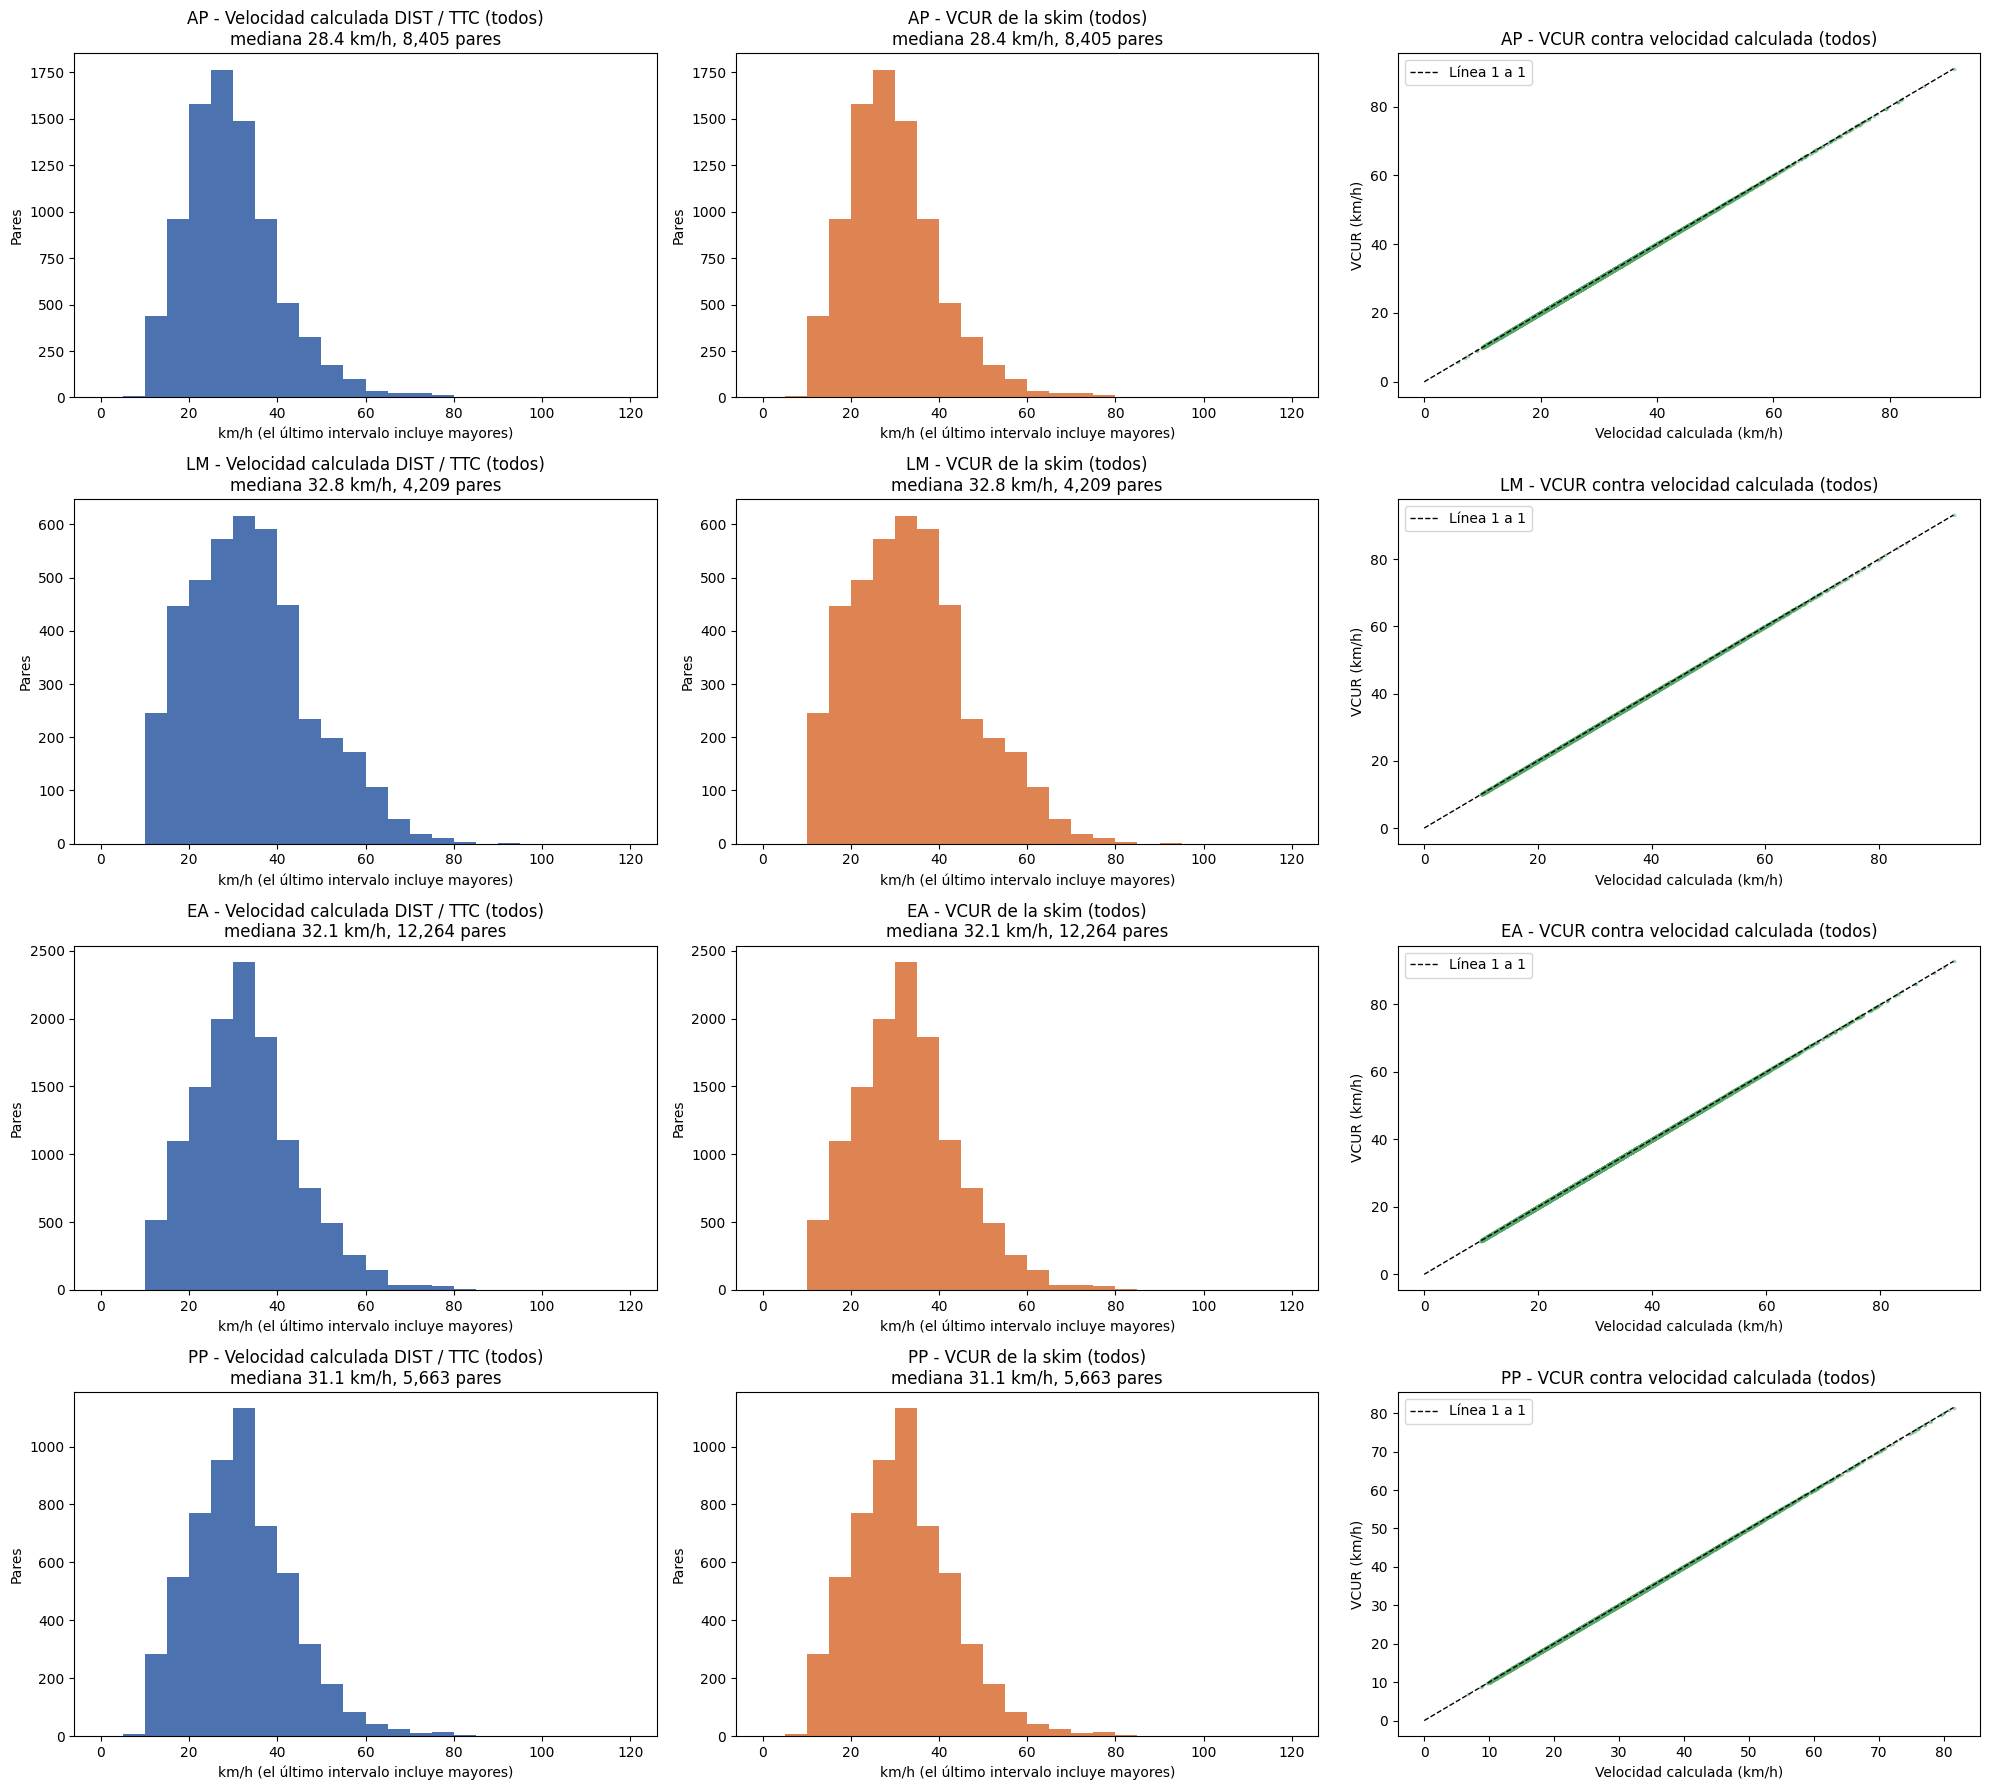

In [7]:
graficar_lado_a_lado(velocidades, "todos")

### Solo pares válidos (sin imposibles)
Mismas reglas del filtro 2: TTC cero, TTC menor a 30 s, velocidad menor a 5 km/h, velocidad mayor al tope por distancia y DIST menor a la mitad de la línea recta.

,Periodo,Pares,Vel. calculada mediana,VCUR mediana,Vel. calculada promedio,VCUR promedio,Diferencia máxima (km/h),Pares con diferencia > 0.01,Correlación
0,AP,8405,28.39,28.39,29.70,29.70,0.0,0,1.0
1,LM,4209,32.82,32.82,33.92,33.92,0.0,0,1.0
2,EA,12264,32.15,32.15,32.91,32.91,0.0,0,1.0
3,PP,5663,31.07,31.07,31.87,31.87,0.0,0,1.0


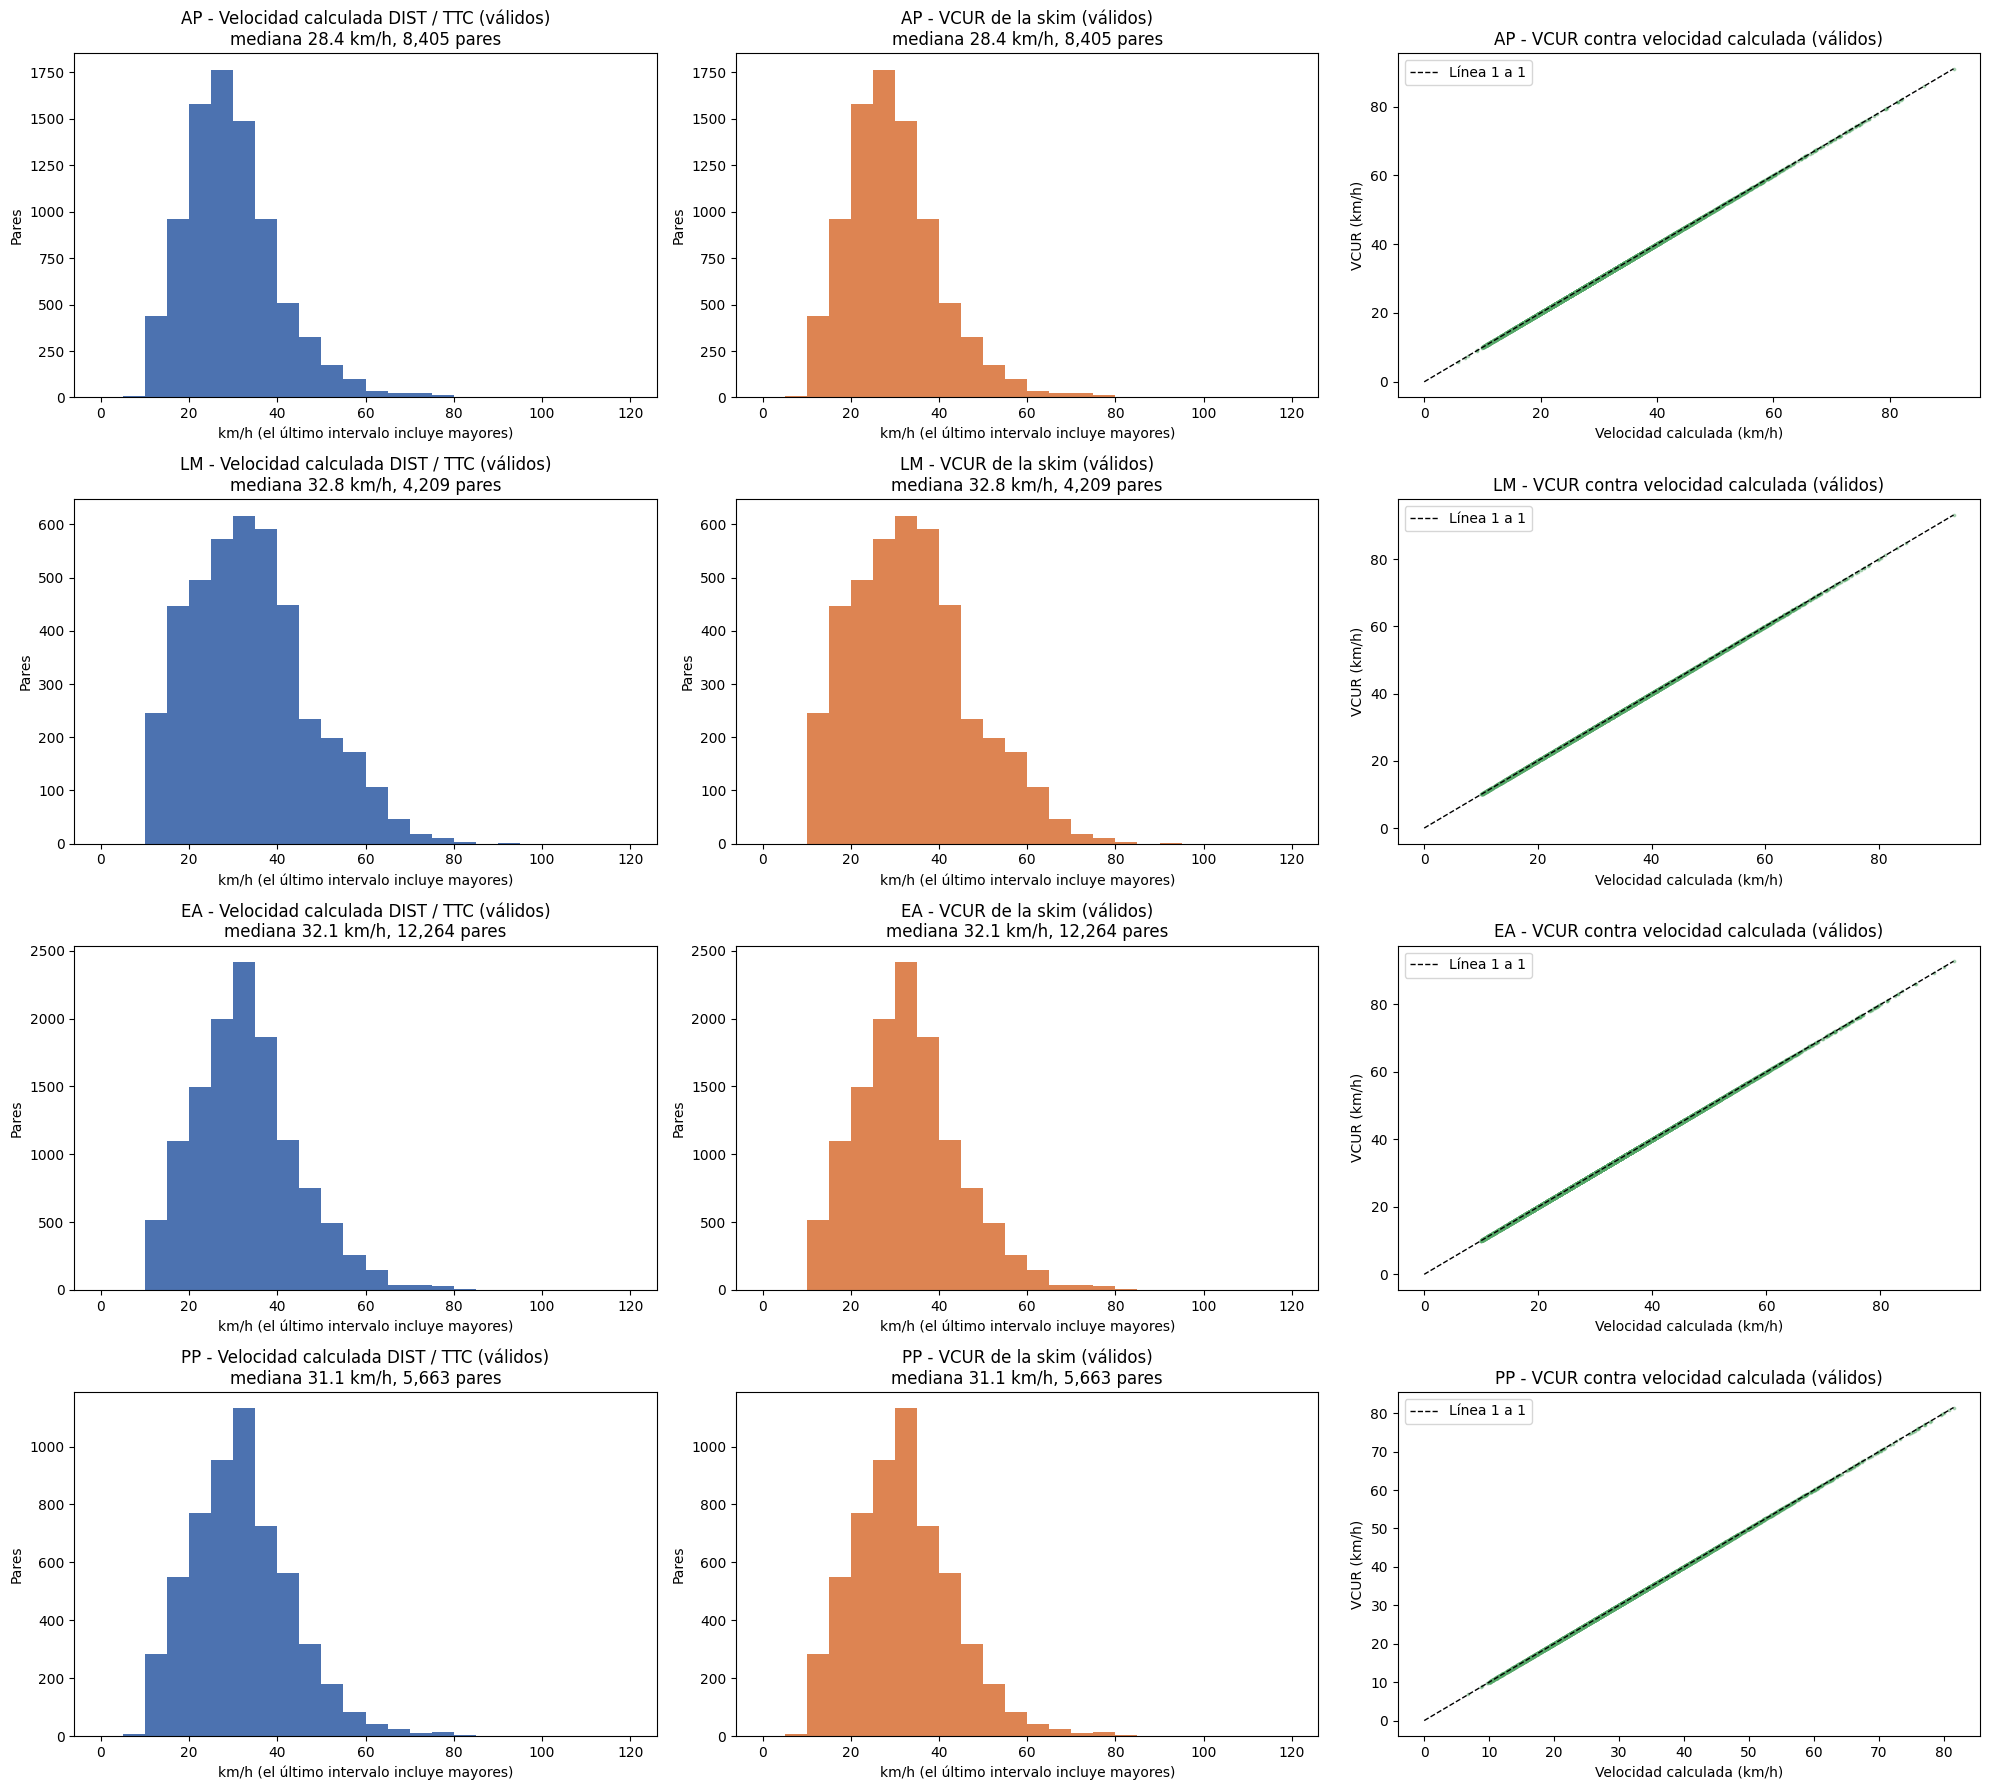

In [8]:
velocidades_validas = {p: v[v["valido"]] for p, v in velocidades.items()}

display(resumen_diferencia(velocidades_validas))
graficar_lado_a_lado(velocidades_validas, "válidos")

## Conclusión
- VCUR es igual a DIST / (TTC / 60) en todos los pares con ruta de los 4 periodos. La diferencia máxima es de 0.00000000000004 km/h (redondeo de la computadora) y la correlación es 1.
- VCUR vale 0 en la diagonal y en los pares sin ruta.
- Con esta base ningún par cumple las reglas de imposibles, así que la comparación con solo pares válidos sale igual que con todos.
- La skim de velocidades está bien: da lo mismo usar VCUR o la velocidad calculada.